### <font color = "gold" > Importer les librairies requises

In [1]:
# Importer les packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

### <font color = "gold" > Importer les données

In [2]:
# Import les données
df = pd.read_csv('wine_dataset.csv')
df.head()

,Class,Alcohol,Malic_acid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,OD280_OD315,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


Ces données sont issues d'analyses chimiques de vins produits dans une même région d'Italie à partir de trois cultivars (cépages) différents. Au total, 178 vins ont été analysés (59, 71 et 48 pour chacun des trois cultivars), et 13 variables chimiques ont été mesurées. Pour plus de détails vous pouvez consulter le site https://archive.ics.uci.edu/dataset/109/wine.
\
L'objectif de ce projet est de réduire la dimension des données afin de pouvoir mieux voir les trois catégories de vins à travers un scatter plot.

**Source :** UCI Machine Learning Repository, dataset « Wine »
- Page du dataset : https://archive.ics.uci.edu/dataset/109/wine
- Téléchargement direct : https://archive.ics.uci.edu/static/public/109/wine.zip
- Fichier utilisé : wine.data, auquel on a ajouté une ligne d'en-tête avec les noms de variables de wine.names, enregistré sous wine_dataset.csv

In [3]:
# Préparer les données :
# - placer la variable cible 'Class' en dernière colonne (même structure que le Raisin Dataset)
# - remplacer les codes 1, 2, 3 par des libellés (catégories et non valeurs numériques)
df['Class'] = df['Class'].map({1: 'Cultivar 1', 2: 'Cultivar 2', 3: 'Cultivar 3'})
df = df[[c for c in df.columns if c != 'Class'] + ['Class']]
df.head()

,Alcohol,Malic_acid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,OD280_OD315,Proline,Class
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,Cultivar 1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,Cultivar 1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,Cultivar 1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,Cultivar 1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,Cultivar 1


####  <font color = "gold" > Explorer les données

In [4]:
# Dimension des données
df.shape

(178, 14)

In [5]:
#infos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Alcalinity_of_ash     178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280_OD315           178 non-null    float64
 12  Proline               178 non-null    int64  
 13  Class                 178 non-null    object 
dtypes: float64(11), int64(2), object(1)
memory usage: 19.6+ KB


In [6]:
# Décrire les données
df.describe()

,Alcohol,Malic_acid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,OD280_OD315,Proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [7]:
# Visualiser les classes suivant les deux premières variables
fig = px.scatter(data_frame=df, x = 'Alcohol', y = 'Malic_acid', color = df.Class.values)
fig.show()

In [8]:
# Visualiser les classes suivant les trois premières variables
fig = px.scatter_3d(data_frame=df, x = 'Alcohol', y = 'Malic_acid', z = 'Ash', color = df.Class.values)
fig.show()

#### <font color = "gold" > Matrice des données

In [9]:
# Les variables utilisées pour le PCA
x = df.iloc[:, :-1].values
x[:5]

array([[1.423e+01, 1.710e+00, 2.430e+00, 1.560e+01, 1.270e+02, 2.800e+00,
        3.060e+00, 2.800e-01, 2.290e+00, 5.640e+00, 1.040e+00, 3.920e+00,
        1.065e+03],
       [1.320e+01, 1.780e+00, 2.140e+00, 1.120e+01, 1.000e+02, 2.650e+00,
        2.760e+00, 2.600e-01, 1.280e+00, 4.380e+00, 1.050e+00, 3.400e+00,
        1.050e+03],
       [1.316e+01, 2.360e+00, 2.670e+00, 1.860e+01, 1.010e+02, 2.800e+00,
        3.240e+00, 3.000e-01, 2.810e+00, 5.680e+00, 1.030e+00, 3.170e+00,
        1.185e+03],
       [1.437e+01, 1.950e+00, 2.500e+00, 1.680e+01, 1.130e+02, 3.850e+00,
        3.490e+00, 2.400e-01, 2.180e+00, 7.800e+00, 8.600e-01, 3.450e+00,
        1.480e+03],
       [1.324e+01, 2.590e+00, 2.870e+00, 2.100e+01, 1.180e+02, 2.800e+00,
        2.690e+00, 3.900e-01, 1.820e+00, 4.320e+00, 1.040e+00, 2.930e+00,
        7.350e+02]])

###<font color = "gold" > PCA from scrath

##### <font color = "wheat" >Standardiser les données

In [10]:
# Standardiser chaque variable : z = (x - moyenne) / écart-type
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x = scaler.fit_transform(x)
x[:5]

array([[ 1.51861254, -0.5622498 ,  0.23205254, -1.16959318,  1.91390522,
         0.80899739,  1.03481896, -0.65956311,  1.22488398,  0.25171685,
         0.36217728,  1.84791957,  1.01300893],
       [ 0.24628963, -0.49941338, -0.82799632, -2.49084714,  0.01814502,
         0.56864766,  0.73362894, -0.82071924, -0.54472099, -0.29332133,
         0.40605066,  1.1134493 ,  0.96524152],
       [ 0.19687903,  0.02123125,  1.10933436, -0.2687382 ,  0.08835836,
         0.80899739,  1.21553297, -0.49840699,  2.13596773,  0.26901965,
         0.31830389,  0.78858745,  1.39514818],
       [ 1.69154964, -0.34681064,  0.4879264 , -0.80925118,  0.93091845,
         2.49144552,  1.46652465, -0.98187536,  1.03215473,  1.18606801,
        -0.42754369,  1.18407144,  2.33457383],
       [ 0.29570023,  0.22769377,  1.84040254,  0.45194578,  1.28198515,
         0.80899739,  0.66335127,  0.22679555,  0.40140444, -0.31927553,
         0.36217728,  0.44960118, -0.03787401]])

In [11]:
# Transformer x standardisé en dataframe
x_df = pd.DataFrame(x, columns=df.columns[:-1])

##### <font color = "wheat" > Matrice de covariance


In [12]:
# Matrice de covariance covmat
cov_mat = x_df.cov()
cov_mat

,Alcohol,Malic_acid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,OD280_OD315,Proline
Alcohol,1.005650,0.094930,0.212740,-0.311988,0.272328,0.290734,0.238153,-0.156810,0.137470,0.549451,-0.072153,0.072752,0.647357
Malic_acid,0.094930,1.005650,0.164972,0.290130,-0.054883,-0.337061,-0.413329,0.294632,-0.221993,0.250392,-0.564467,-0.370794,-0.193095
Ash,0.212740,0.164972,1.005650,0.445872,0.288206,0.129708,0.115727,0.187283,0.009706,0.260350,-0.075089,0.003933,0.224890
Alcalinity_of_ash,-0.311988,0.290130,0.445872,1.005650,-0.083804,-0.322928,-0.353355,0.363966,-0.198442,0.018838,-0.275503,-0.278332,-0.443086
Magnesium,0.272328,-0.054883,0.288206,-0.083804,1.005650,0.215613,0.196890,-0.257742,0.237776,0.201080,0.055711,0.066377,0.395573
Total_phenols,0.290734,-0.337061,0.129708,-0.322928,0.215613,1.005650,0.869448,-0.452477,0.615873,-0.055448,0.436132,0.703904,0.500929
Flavanoids,0.238153,-0.413329,0.115727,-0.353355,0.196890,0.869448,1.005650,-0.540939,0.656379,-0.173353,0.546549,0.791641,0.496985
Nonflavanoid_phenols,-0.156810,0.294632,0.187283,0.363966,-0.257742,-0.452477,-0.540939,1.005650,-0.367912,0.139843,-0.264123,-0.506113,-0.313144
Proanthocyanins,0.137470,-0.221993,0.009706,-0.198442,0.237776,0.615873,0.656379,-0.367912,1.005650,-0.025393,0.297214,0.522000,0.332283
Color_intensity,0.549451,0.250392,0.260350,0.018838,0.201080,-0.055448,-0.173353,0.139843,-0.025393,1.005650,-0.524761,-0.431238,0.317886


##### <font color = "wheat" >Vecteurs propres et valeurs propres

In [13]:
from numpy import linalg as LA
# Vecteurs propres et valeurs propres
# eigh : pour une matrice symétrique (comme la covariance) -> valeurs réelles (pas de nombres complexes)
val_propres, vecteurs_propres = LA.eigh(cov_mat)

# eigh renvoie les valeurs propres en ordre croissant -> trier en ordre décroissant
idx = np.argsort(val_propres)[::-1]
val_propres = val_propres[idx]
vecteurs_propres = vecteurs_propres[:, idx]

for i in range(len(val_propres)):
    print(f'Vecteur propre {i + 1}: \n {vecteurs_propres[:, i]}')
    print(f'Valeur propre {i + 1}: \n {val_propres[i]}')
    print('------------------------------')


Vecteur propre 1: 
 [-0.1443294   0.24518758  0.00205106  0.23932041 -0.14199204 -0.39466085
 -0.4229343   0.2985331  -0.31342949  0.0886167  -0.29671456 -0.37616741
 -0.28675223]
Valeur propre 1: 
 4.732436977583586
------------------------------
Vecteur propre 2: 
 [-0.48365155 -0.22493093 -0.31606881  0.0105905  -0.299634   -0.06503951
  0.00335981 -0.02877949 -0.03930172 -0.52999567  0.27923515  0.16449619
 -0.36490283]
Valeur propre 2: 
 2.5110809296451237
------------------------------
Vecteur propre 3: 
 [-0.20738262  0.08901289  0.6262239   0.61208035  0.13075693  0.14617896
  0.1506819   0.17036816  0.14945431 -0.13730621  0.08522192  0.16600459
 -0.12674592]
Valeur propre 3: 
 1.4542418678464661
------------------------------
Vecteur propre 4: 
 [ 0.0178563  -0.53689028  0.21417556 -0.06085941  0.35179658 -0.19806835
 -0.15229479  0.20330102 -0.39905653 -0.06592568  0.42777141 -0.18412074
  0.23207086]
Valeur propre 4: 
 0.924165866824874
------------------------------
Vecteu

##### <font color = "wheat" >Composantes principales

In [14]:
# matrice des composantes principales
comp_prin_matrix = np.dot(x, vecteurs_propres)

In [15]:
# Créer une liste des noms des différentes composantes
df_pca = pd.DataFrame(comp_prin_matrix, columns = ['PC' + str(i + 1) for i in range(13)])
df_pca.head()


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13
0,-3.316751,-1.443463,-0.165739,0.215631,0.693043,-0.223880,-0.596427,0.065139,0.641443,1.020956,0.451563,-0.540810,0.066239
1,-2.209465,0.333393,-2.026457,0.291358,-0.257655,-0.927120,-0.053776,1.024416,-0.308847,0.159701,0.142657,-0.388238,-0.003637
2,-2.516740,-1.031151,0.982819,-0.724902,-0.251033,0.549276,-0.424205,-0.344216,-1.177834,0.113361,0.286673,-0.000584,-0.021717
3,-3.757066,-2.756372,-0.176192,-0.567983,-0.311842,0.114431,0.383337,0.643593,0.052544,0.239413,-0.759584,0.242020,0.369484
4,-1.008908,-0.869831,2.026688,0.409766,0.298458,-0.406520,-0.444074,0.416700,0.326819,-0.078366,0.525945,0.216664,0.079364


##### <font color = "wheat" >Calcul des parts de variance (pdv)

In [16]:
# Dictionnaire des proportion de variance
dic = {
       'val_propres' : val_propres,
       'proportion' : (val_propres/val_propres.sum())*100
        }
pdv = pd.DataFrame(dic)
pdv['pct_cumule'] = pdv['proportion'].cumsum()
pdv.index = ['PC' + str(i + 1) for i in range(13)]
pdv

,val_propres,proportion,pct_cumule
PC1,4.732437,36.198848,36.198848
PC2,2.511081,19.207490,55.406338
PC3,1.454242,11.123631,66.529969
PC4,0.924166,7.069030,73.598999
PC5,0.858049,6.563294,80.162293
PC6,0.645282,4.935823,85.098116
PC7,0.554141,4.238679,89.336795
PC8,0.350466,2.680749,92.017544
PC9,0.290512,2.222153,94.239698
PC10,0.252320,1.930019,96.169717


##### <font color = "wheat" >Visualiser la proportion variance

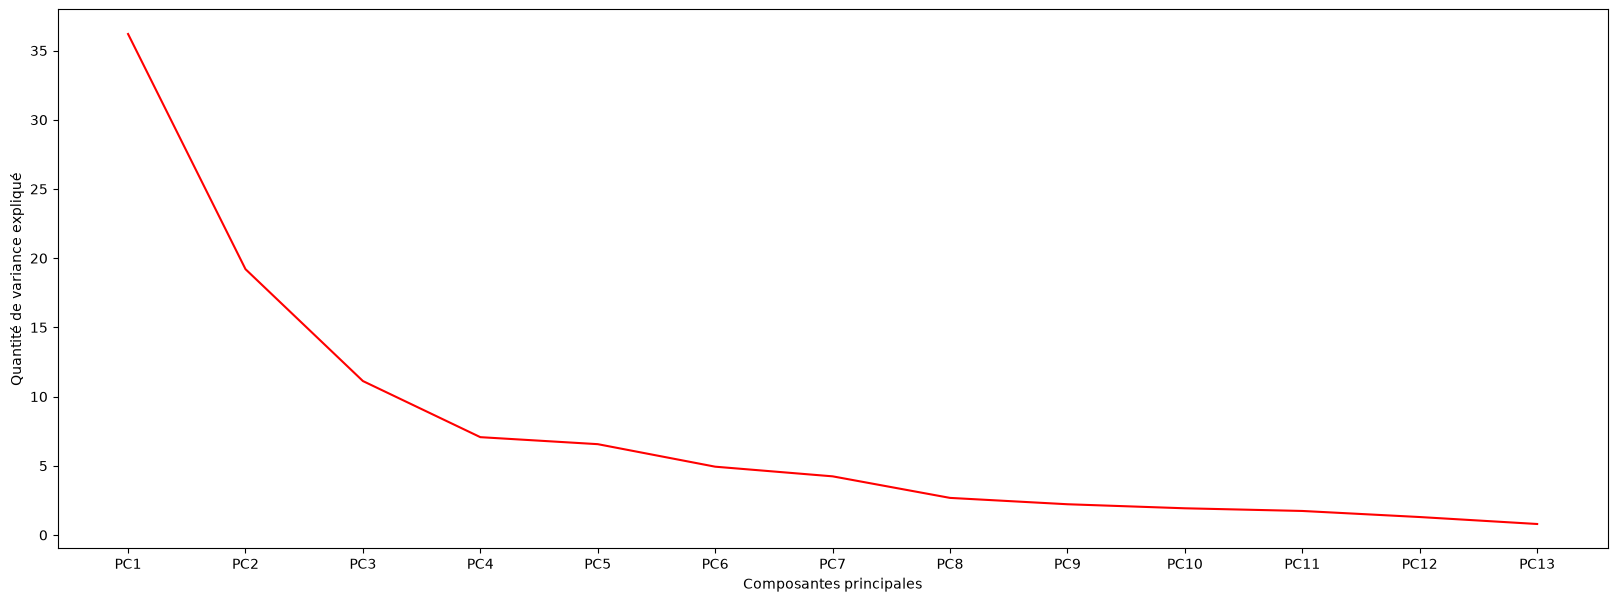

In [17]:
# Plot des parts de variance de chaque composantes
plt.figure(figsize=(20, 7))
plt.plot(df_pca.columns, pdv['proportion'], c='r')
plt.ylabel('Quantité de variance expliqué')
plt.xlabel('Composantes principales')
plt.show()

In [18]:
# Part de variance des deux composantes
print(f'Part de variance des deux composantes : {pdv.iloc[1, 2]}')

Part de variance des deux composantes : 55.40633835693525


##### <font color = "wheat" > Nouveau jeu de données réduit

In [19]:
# Selectionner les composantes qui maximisent la part de variance

New_df = df_pca.iloc[:, :2]
New_df.head()

,PC1,PC2
0,-3.316751,-1.443463
1,-2.209465,0.333393
2,-2.516740,-1.031151
3,-3.757066,-2.756372
4,-1.008908,-0.869831


##### <font color = "wheat" >Visualiser les donneées suivant les deux premiers composantes

In [20]:
# Visualiser les classes suivant les deux composantes
fig = px.scatter(New_df.apply(np.real), x = 'PC1', y = 'PC2', color = df.Class.values)
fig.show()


### <font color = "gold" > PCA from sklearn

In [21]:
# Importer PCA model
from sklearn.decomposition import PCA

In [22]:
# Initier l'instance PCA avec 2 composantes
pca = PCA(n_components=2)
# Matrice des composantes avec fonction fit_transform
feature_pca = pca.fit_transform(x)

In [23]:
# Nouveau dataframe des deux composantes
New_def_1 = pd.DataFrame(feature_pca, columns = ['PC1', 'PC2'])
New_def_1.head()

,PC1,PC2
0,3.316751,1.443463
1,2.209465,-0.333393
2,2.516740,1.031151
3,3.757066,2.756372
4,1.008908,0.869831


In [24]:
# Part de variance des 2 composantes
round(sum(pca.explained_variance_ratio_*100), 2)

np.float64(55.41)

In [25]:
# Visualiser les classes suivant les deux composantes
# Visualiser les classes suivant les deux composantes
fig = px.scatter(data_frame=New_def_1, x = 'PC1', y = 'PC2', color = df.Class.values)
fig.show()

### <font color = "gold" > Interprétation du PCA

In [26]:
# install mlxtend
!pip install mlxtend


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


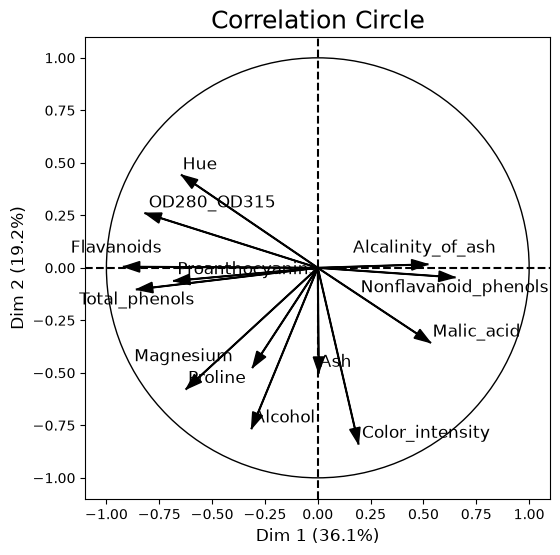

In [27]:
# import plot_pca_correlation_graph
from mlxtend.plotting import plot_pca_correlation_graph
figure, correlation_matrix = plot_pca_correlation_graph(x,
                                                        df.columns[:-1],
                                                       dimensions= (1,2))

In [28]:
# Affichar la matrice de corrélation
correlation_matrix 

,Dim 1,Dim 2
Alcohol,-0.313093,-0.764257
Malic_acid,0.531885,-0.355432
Ash,0.004449,-0.499446
Alcalinity_of_ash,0.519157,0.016735
Magnesium,-0.308023,-0.473476
Total_phenols,-0.856137,-0.102774
Flavanoids,-0.917470,0.005309
Nonflavanoid_phenols,0.647607,-0.045477
Proanthocyanins,-0.679922,-0.062104
Color_intensity,0.192236,-0.837489


In [29]:
# matrice de correlation entre les variables
df[df.columns[:-1]].corr()

,Alcohol,Malic_acid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,OD280_OD315,Proline
Alcohol,1.000000,0.094397,0.211545,-0.310235,0.270798,0.289101,0.236815,-0.155929,0.136698,0.546364,-0.071747,0.072343,0.643720
Malic_acid,0.094397,1.000000,0.164045,0.288500,-0.054575,-0.335167,-0.411007,0.292977,-0.220746,0.248985,-0.561296,-0.368710,-0.192011
Ash,0.211545,0.164045,1.000000,0.443367,0.286587,0.128980,0.115077,0.186230,0.009652,0.258887,-0.074667,0.003911,0.223626
Alcalinity_of_ash,-0.310235,0.288500,0.443367,1.000000,-0.083333,-0.321113,-0.351370,0.361922,-0.197327,0.018732,-0.273955,-0.276769,-0.440597
Magnesium,0.270798,-0.054575,0.286587,-0.083333,1.000000,0.214401,0.195784,-0.256294,0.236441,0.199950,0.055398,0.066004,0.393351
Total_phenols,0.289101,-0.335167,0.128980,-0.321113,0.214401,1.000000,0.864564,-0.449935,0.612413,-0.055136,0.433681,0.699949,0.498115
Flavanoids,0.236815,-0.411007,0.115077,-0.351370,0.195784,0.864564,1.000000,-0.537900,0.652692,-0.172379,0.543479,0.787194,0.494193
Nonflavanoid_phenols,-0.155929,0.292977,0.186230,0.361922,-0.256294,-0.449935,-0.537900,1.000000,-0.365845,0.139057,-0.262640,-0.503270,-0.311385
Proanthocyanins,0.136698,-0.220746,0.009652,-0.197327,0.236441,0.612413,0.652692,-0.365845,1.000000,-0.025250,0.295544,0.519067,0.330417
Color_intensity,0.546364,0.248985,0.258887,0.018732,0.199950,-0.055136,-0.172379,0.139057,-0.025250,1.000000,-0.521813,-0.428815,0.316100


##### <font color = "wheat" > Interprétation

- **PC1 (36,2 % de la variance) : la richesse en composés phénoliques.** Elle est fortement corrélée à Flavanoids (|r| ≈ 0,92), Total_phenols (0,86), OD280_OD315 (0,82), Proanthocyanins (0,68), Hue (0,64) et Proline (0,62), qui varient dans le même sens. Elle les oppose à Nonflavanoid_phenols (0,65), Malic_acid (0,53) et Alcalinity_of_ash (0,52), qui varient en sens inverse. Le signe de l'axe est arbitraire (il peut différer entre la PCA « from scratch » et celle de sklearn), seule la direction compte.
- **PC2 (19,2 % de la variance) : l'intensité du vin.** Elle est portée par Color_intensity (|r| ≈ 0,84) et Alcohol (0,76), puis Proline (0,58), Ash (0,50) et Magnesium (0,47).

### <font color = "gold" > Conclusion

Après standardisation, les deux premières composantes conservent **55,4 %** de l'information des 13 variables. C'est nettement moins que pour les raisins : les variables chimiques sont moins redondantes entre elles, et il faudrait 5 composantes pour dépasser 80 %. Le scatter plot (PC1, PC2) sépare pourtant bien les trois cultivars :
- **Cultivar 1** et **Cultivar 3** s'opposent le long de PC1 : le cultivar 1 est riche en flavonoïdes (≈ 3,0 en moyenne contre ≈ 0,8 pour le cultivar 3) et en proline (≈ 1 116 contre ≈ 630) ;
- **Cultivar 2** se distingue le long de PC2 : vins moins alcoolisés (≈ 12,3 % contre ≈ 13,7 % et ≈ 13,2 %) et moins colorés (Color_intensity ≈ 3,1 contre ≈ 5,5 et ≈ 7,4).

Une régression logistique entraînée sur ces deux composantes seulement atteint environ **92 % d'accuracy** sur un jeu de test (cellule suivante), contre 40 % en prédisant toujours la classe majoritaire. Même avec 55 % de la variance, les deux premiers axes portent l'essentiel de l'information utile pour distinguer les cultivars.

## <font color='gold'> Clustering : K-Means et CAH

On cherche maintenant à regrouper les vins **sans utiliser la variable Class** (apprentissage non supervisé), en suivant les étapes du notebook Customer_Segmentation. On comparera ensuite les classes trouvées avec les vraies catégories.

### <font color='gold'> Preparation des données

In [30]:
# renommer les index
df.index = ['Vin' + str(i+1) for i in range(len(df))]
df.head()

,Alcohol,Malic_acid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,OD280_OD315,Proline,Class
Vin1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,Cultivar 1
Vin2,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,Cultivar 1
Vin3,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,Cultivar 1
Vin4,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,Cultivar 1
Vin5,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,Cultivar 1


In [31]:
# Données en format matriciel (sans la variable Class : le clustering est non supervisé)
x = df.iloc[:, :-1].values
x[:5]

array([[1.423e+01, 1.710e+00, 2.430e+00, 1.560e+01, 1.270e+02, 2.800e+00,
        3.060e+00, 2.800e-01, 2.290e+00, 5.640e+00, 1.040e+00, 3.920e+00,
        1.065e+03],
       [1.320e+01, 1.780e+00, 2.140e+00, 1.120e+01, 1.000e+02, 2.650e+00,
        2.760e+00, 2.600e-01, 1.280e+00, 4.380e+00, 1.050e+00, 3.400e+00,
        1.050e+03],
       [1.316e+01, 2.360e+00, 2.670e+00, 1.860e+01, 1.010e+02, 2.800e+00,
        3.240e+00, 3.000e-01, 2.810e+00, 5.680e+00, 1.030e+00, 3.170e+00,
        1.185e+03],
       [1.437e+01, 1.950e+00, 2.500e+00, 1.680e+01, 1.130e+02, 3.850e+00,
        3.490e+00, 2.400e-01, 2.180e+00, 7.800e+00, 8.600e-01, 3.450e+00,
        1.480e+03],
       [1.324e+01, 2.590e+00, 2.870e+00, 2.100e+01, 1.180e+02, 2.800e+00,
        2.690e+00, 3.900e-01, 1.820e+00, 4.320e+00, 1.040e+00, 2.930e+00,
        7.350e+02]])

In [ ]:
# Importer normalize
from sklearn.preprocessing import normalize
# Normaliser x
x = normalize(x)
x[:5]

array([[1.32644724e-02, 1.59397384e-03, 2.26512072e-03, 1.45415157e-02,
        1.18382852e-01, 2.61001565e-03, 2.85237424e-03, 2.61001565e-04,
        2.13461994e-03, 5.25731723e-03, 9.69434383e-04, 3.65402190e-03,
        9.92738094e-01],
       [1.25128005e-02, 1.68733218e-03, 2.02859038e-03, 1.06169216e-02,
        9.47939430e-02, 2.51203949e-03, 2.61631283e-03, 2.46464252e-04,
        1.21336247e-03, 4.15197470e-03, 9.95336401e-04, 3.22299406e-03,
        9.95336401e-01],
       [1.10630135e-02, 1.98394467e-03, 2.24454758e-03, 1.56361741e-02,
        8.49061068e-02, 2.35383266e-03, 2.72372065e-03, 2.52196357e-04,
        2.36223921e-03, 4.77491769e-03, 8.65874158e-04, 2.66487484e-03,
        9.96175609e-01],
       [9.67995483e-03, 1.31356381e-03, 1.68405616e-03, 1.13168574e-02,
        7.61193386e-02, 2.59344649e-03, 2.35094241e-03, 1.61669392e-04,
        1.46849698e-03, 5.25425523e-03, 5.79315321e-04, 2.32399751e-03,
        9.96961249e-01],
       [1.77749811e-02, 3.47712999e-

In [33]:
# Importer PCA
from sklearn.decomposition import PCA
#Instantier le modèle PCA avec n_components = 2
pca_model= PCA(n_components = 2)
# Matrice des 2 composantes
feature_pca = pca_model.fit_transform(x)
# Convertir la matrice features_pca en dataframe
New_df = pd.DataFrame(feature_pca, columns = ['PC1', 'PC2'])

In [34]:
# Part de variance des 2 composantes
np.round(sum(pca_model.explained_variance_ratio_)*100, 2)

np.float64(99.07)

In [35]:
# Function de visualisation du diagramme en barre des nombres d'observations.
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

In [36]:
# Function de visualisuation des classes
def scatter_plot(New_df,Pred):
  fig = px.scatter(New_df, x='PC1', y='PC2', color=Pred.astype(str))
  fig.show()

### <font color='gold'> Kmeans

In [37]:
# Importer KMeans
from sklearn.cluster import KMeans

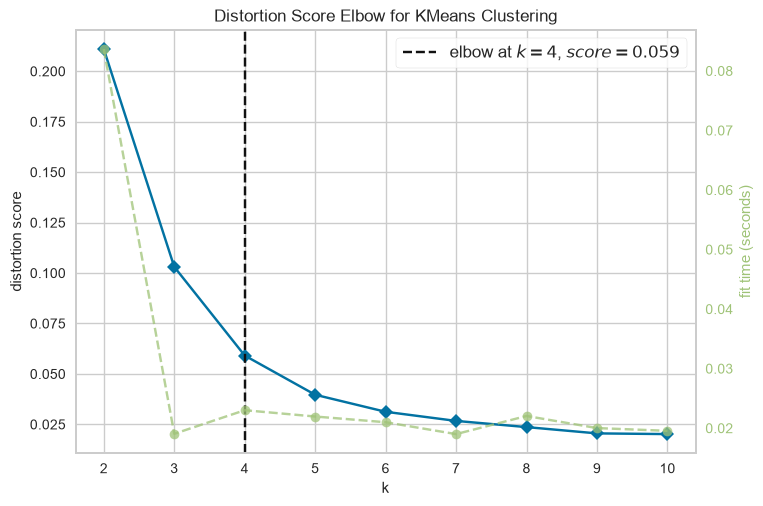

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [38]:
# importer KELbowVisualizer
import setuptools  # charge le module distutils de remplacement pour yellowbrick
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init='random', max_iter=500)
kmeans_model._estimator_type = "clusterer"  # contournement : yellowbrick 1.5 + scikit-learn ≥ 1.6
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=10)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

**Choix de k = 3.** La courbe du coude ne présente pas de cassure nette (le point proposé par KElbowVisualizer varie d'une exécution à l'autre). On retient k = 3 : c'est le nombre de cultivars du jeu de données, ce qui permet de comparer les classes trouvées avec les vraies catégories.

In [39]:
# instantier le modèle
kmeans_model = KMeans(n_clusters = 3, init = 'random', max_iter=500, random_state=42)
# Entrainer le modèle
kmeans_model.fit(x)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",500
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",42
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


#### <font color='teal'> Prédiction

In [40]:
# Prediction de la partition des données
kmeans_partition = kmeans_model.predict(x)
# Afficher la partition
kmeans_partition[: 100]

array([2, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 1,
       2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 2, 1,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 0, 1, 0, 0, 1,
       1, 1, 1, 0, 2, 0, 1, 1, 2, 0, 0, 0, 1, 0, 0, 2, 1, 1, 1, 0, 1, 1,
       2, 2, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0], dtype=int32)

In [41]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts()
val

1    81
2    60
0    37
Name: count, dtype: int64

In [42]:
# Diagramme en barre des nombres d'observations
bar_plot(val)

In [43]:
# Visualiser les classes
scatter_plot(New_df, kmeans_partition)

##### <font color='teal'> Indice de silhouette de la partition du Kmeans

In [44]:
# Silhouette score
from sklearn.metrics import silhouette_score
siil_kmeans = silhouette_score(x, kmeans_partition)
print("Silhouette score for KMeans clustering: ", siil_kmeans)

Silhouette score for KMeans clustering:  0.5233461282286351


### <font color='gold'> CAH

In [45]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram

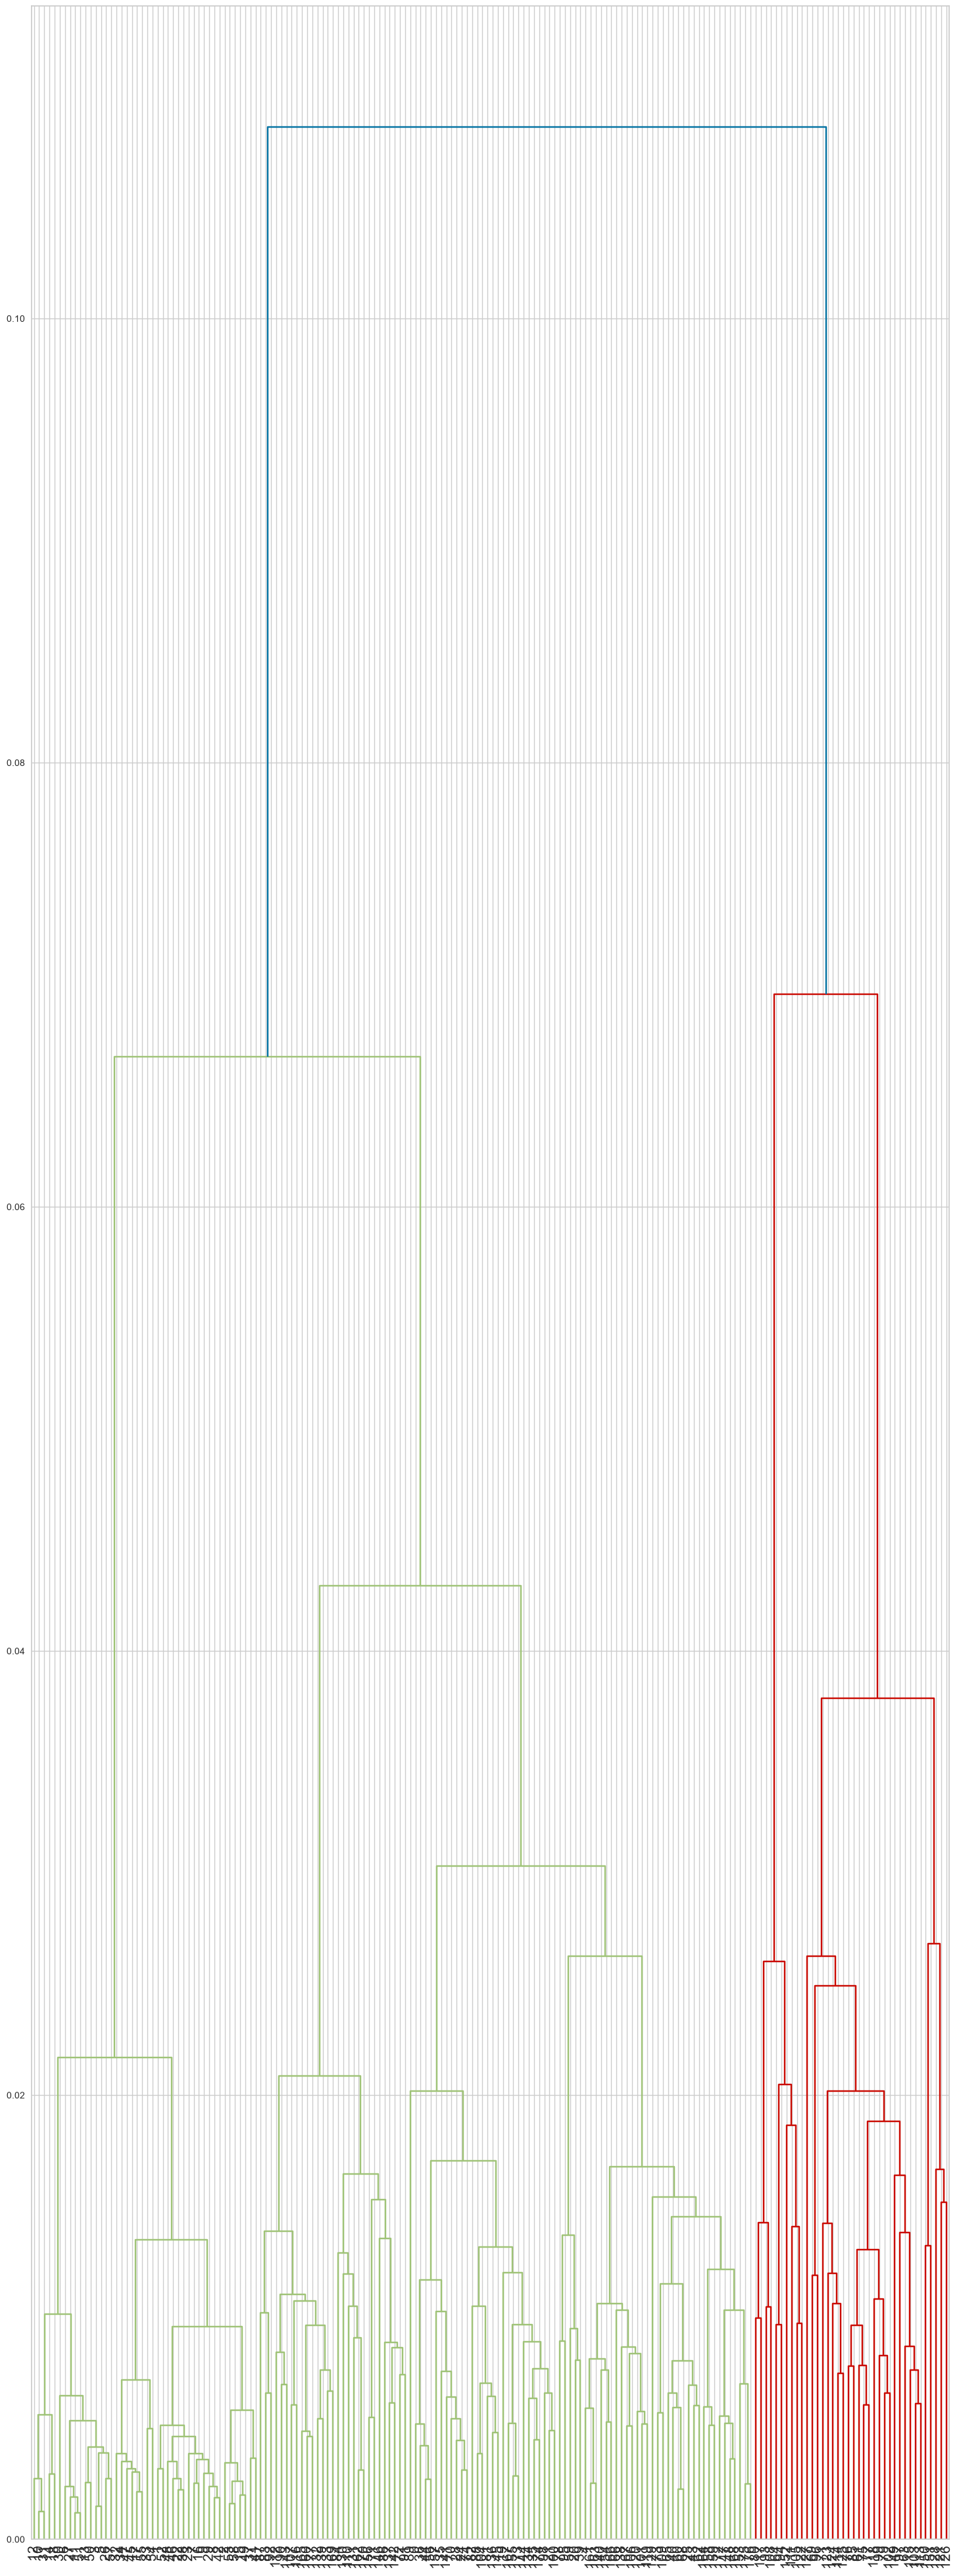

In [46]:
# Visualiser le dendrograme
import matplotlib.pyplot as plt
Z = linkage(x, 'average')# matrice des liaisons
plt.figure(figsize=(18, 50))
dendro = dendrogram(Z, leaf_font_size=15, orientation = 'top')

In [47]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters = 3, linkage = 'average')
# Entrainer le modèle
cah_model.fit(x)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",3
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" is accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and affinity is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'average'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",None
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False


In [48]:
# Prédire la partition des données
cah_partition = cah_model.fit_predict(x)
# Afficher la partition
cah_partition[: 100]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 2, 0,
       0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 2, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 2, 2, 0, 1, 1, 0, 1])

In [49]:
# Nombre d'observations dans chaque classe
val1  = pd.Series(cah_partition).value_counts()
val1

0    140
1     28
2     10
Name: count, dtype: int64

In [50]:
# Diagramme en barre des nombres d'observations
bar_plot(val1)

In [51]:
# Visualiser les classes
scatter_plot(New_df, cah_partition)

In [52]:
# Silhouette score
sil_cah = silhouette_score(x, cah_partition)
print("Silhouette score for Agglomerative clustering: ", sil_cah)

Silhouette score for Agglomerative clustering:  0.4576761698455429


In [53]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [siil_kmeans, sil_cah]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [54]:
# les indidivus
cluster_name = []
for i in range(3):
    cluster_name.append(list(df.index[kmeans_partition == i]))

In [55]:
# Les individus de la classe 0
print("Individus de la classe 0 :")
print(cluster_name[0])

Individus de la classe 0 :
['Vin62', 'Vin64', 'Vin65', 'Vin70', 'Vin72', 'Vin76', 'Vin77', 'Vin78', 'Vin80', 'Vin81', 'Vin86', 'Vin94', 'Vin95', 'Vin97', 'Vin100', 'Vin103', 'Vin104', 'Vin106', 'Vin109', 'Vin112', 'Vin114', 'Vin115', 'Vin116', 'Vin118', 'Vin119', 'Vin122', 'Vin123', 'Vin124', 'Vin125', 'Vin126', 'Vin127', 'Vin128', 'Vin129', 'Vin150', 'Vin151', 'Vin152', 'Vin153']


#### <font color='teal'> Comparer les classes trouvées avec les vraies catégories

In [56]:
# Classes K-Means / vraies catégories
pd.crosstab(df.Class, kmeans_partition, rownames=['Vraie catégorie'], colnames=['Classe K-Means'])

Classe K-Means,0,1,2
Vraie catégorie,,,
Cultivar 1,0,8,51
Cultivar 2,33,33,5
Cultivar 3,4,40,4


In [57]:
# Classes CAH / vraies catégories
pd.crosstab(df.Class, cah_partition, rownames=['Vraie catégorie'], colnames=['Classe CAH'])

Classe CAH,0,1,2
Vraie catégorie,,,
Cultivar 1,59,0,0
Cultivar 2,37,25,9
Cultivar 3,44,3,1


##### <font color='teal'> Interprétation du clustering

- **Silhouette** : K-Means obtient le meilleur score (≈ 0,52 contre ≈ 0,46 pour la CAH). La CAH produit des classes très déséquilibrées (140 / 28 / 10 vins). On retient **K-Means** comme meilleur modèle.
- **Comparaison avec les cultivars** : la classe K-Means 2 retrouve bien le **Cultivar 1** (51 des 59 vins). Les cultivars 2 et 3 sont en revanche mélangés entre les classes 0 et 1.
- **Pourquoi ?** `normalize` ramène chaque vin à une norme 1. Proline (plusieurs centaines) et Magnesium (≈ 100) sont bien plus grandes que les autres variables et dominent la norme : les classes se font surtout selon la teneur en proline, ≈ 415 (classe 0), ≈ 629 (classe 1) et ≈ 1 110 (classe 2). Le Cultivar 1 se distingue justement par sa proline élevée, d'où sa bonne détection. Les cultivars 2 et 3 ont des teneurs en proline proches et ne se séparent que par d'autres variables (flavonoïdes, couleur), écrasées par la normalisation. Pour la même raison, la PCA sur les données normalisées affiche 99,1 % de variance sur 2 composantes (contre 55,4 % après standardisation dans la première partie).

### <font color='gold'> Meilleur modèle (K-Means) pour le déploiement

In [58]:
from scipy.spatial.distance import cdist

# Partition du meilleur modèle
best_partition = kmeans_partition
# Calculer les centroïdes
classes = np.unique(best_partition)
centroides = np.array([x[best_partition == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
def predire_classe(nouvelle_obs):
    obs = normalize(np.array(nouvelle_obs, dtype=float).reshape(1, -1))
    distances = cdist(obs, centroides)
    return classes[distances.argmin()]

In [59]:
# Test rapide
print("Classe prédite  :", predire_classe(df.iloc[0, :-1].values))
print("Classe réelle du K-Means:", best_partition[0])

Classe prédite  : 2
Classe réelle du K-Means: 2


#### <font color='teal'> Interpréter les classes

Avant de livrer l'application, il faut savoir **ce que représente chaque classe**, pour afficher un
message compréhensible par l'utilisateur final. On regarde le profil moyen de chaque classe.

In [60]:
# Profil moyen de chaque classe
profil = df.iloc[:, :-1].groupby(best_partition).mean().round(2)
profil

,Alcohol,Malic_acid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,OD280_OD315,Proline
0,12.33,2.24,2.31,20.92,97.84,2.29,2.14,0.35,1.59,3.65,1.00,2.69,415.16
1,12.88,2.66,2.35,20.24,98.43,2.00,1.46,0.41,1.44,5.46,0.87,2.28,629.25
2,13.58,1.96,2.42,17.62,102.68,2.70,2.73,0.31,1.80,5.38,1.04,3.01,1110.28


In [61]:
# Noms des classes
noms_classes = {
    0: "vin à faible teneur en proline",
    1: "vin à teneur moyenne en proline",
    2: "vin riche en proline (profil Cultivar 1)",
}

In [62]:
# Sauvegarder le modèle de clustering pour l'application Streamlit
import joblib
joblib.dump({'modele': 'K-Means', 'variables': list(df.columns[:-1]), 'classes': classes,
             'centroides': centroides, 'noms_classes': noms_classes}, 'wine_clustering.joblib')

['wine_clustering.joblib']

### <font color = "gold" > Sauvegarde du modèle pour le déploiement

In [63]:
# Pipeline : standardisation + PCA, puis une régression logistique sur (PC1, PC2)
# pour prédire la variété d'une nouvelle observation dans l'application Streamlit
import joblib
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X = df.iloc[:, :-1]
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

model = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2)),
    ('clf', LogisticRegression()),
])
model.fit(X_train, y_train)
print(f'Accuracy sur le jeu de test : {model.score(X_test, y_test):.3f}')

# Réentraîner sur toutes les données et sauvegarder
model.fit(X, y)
joblib.dump(model, 'wine_pca_model.joblib')

Accuracy sur le jeu de test : 0.917


['wine_pca_model.joblib']